# Coding 1: Simulate the monthly model

QIDIAN XING  
MICHAEL SUHERMAN  
GUS GUENTHER  
ENDI ZONANA

MGMTMFE 431 Homework 1. Six-notebook organization: October 5, 2026.

**Formal task:** specify the monthly state-space model, simulate from its stationary prior, and plot observations and the true latent component.

This notebook is independent: start its kernel in this directory and use Restart Kernel → Run All. No other notebook or project module is required. AI assistance is disclosed in the separate submission record.

## Parameters and fixed seeds

Monthly rates are in percentage points. Q and H are variances. Experimental settings are unchanged from the verified project.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import hashlib
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from numba import njit
from scipy.optimize import minimize
from IPython.display import display, HTML

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.2, 'figure.dpi': 120,
})
COLORS = {'monthly': '#1e4e79', 'annual': '#9b4b2b',
          'benchmark': '#52665f', 'data': '#454545'}

Matplotlib is building the font cache; this may take a moment.


In [2]:
TRUE_PARAMETERS = {'mu': 0.2, 'phi': 0.9, 'Q': 0.04, 'H': 0.01}
T_sample = 300
SIMULATION_SEED = 431300

## Mathematical specification
Let $\alpha_t$ be the scalar mean-zero latent state. The constant intercept is $\mu$:
$$y_t=\mu+\alpha_t+\eta_t,\qquad \alpha_{t+1}=\phi\alpha_t+\epsilon_{t+1}.$$
Assume time-invariant coefficients, $|\phi|<1$, $Q,H>0$, independent sequences
$\eta_t\sim N(0,H)$ and $\epsilon_{t+1}\sim N(0,Q)$, with independence across time,
between sequences, and from the stationary initial state.
$$\alpha_1\sim N\left(0,\frac{Q}{1-\phi^2}\right),\quad
a_{1|0}=0,\quad P_{1|0}=\frac{Q}{1-\phi^2}.$$
Here $a_{t|s}=E(\alpha_t\mid y_{1:s};\theta)$ and $P_{t|s}$ is its conditional
variance. The scalar system matrices are $Z=R=1$, $d=\mu$, $T=\phi$, $c=0$.
Stationarity solves $V=\phi^2V+Q$. A prior mean of zero does **not** mean that
simulation fixes the initial state at zero.

## Readable simulation functions

One generator draws the initial state, state shocks and observation shocks in the original order.

In [3]:
@dataclass(frozen=True)
class Parameters:
    mu: float
    phi: float
    Q: float
    H: float

    def __post_init__(self):
        if not (abs(self.phi) < 1 and self.Q > 0 and self.H > 0):
            raise ValueError("Require |phi|<1, Q>0 and H>0")

    def vector(self):
        return np.array([self.mu, self.phi, self.Q, self.H])

    def reported(self):
        return np.array([self.mu, self.phi, np.sqrt(self.Q), np.sqrt(self.H)])

In [4]:
def simulate(T_sample, p, seed):
    """Use a stationary initial draw and independent state/observation shocks."""
    rng = np.random.default_rng(seed)
    alpha = np.empty(T_sample)
    alpha[0] = rng.normal(0, np.sqrt(p.Q / (1 - p.phi**2)))
    epsilon = rng.normal(0, np.sqrt(p.Q), T_sample - 1)
    eta = rng.normal(0, np.sqrt(p.H), T_sample)
    for t in range(1, T_sample):
        alpha[t] = p.phi * alpha[t-1] + epsilon[t-1]
    return p.mu + alpha + eta, alpha, eta

In [5]:
truth = Parameters(**TRUE_PARAMETERS)
y_sim, alpha_true, eta_true = simulate(T_sample, truth, SIMULATION_SEED)
np.testing.assert_allclose(y_sim, truth.mu + alpha_true + eta_true)
assert np.isclose(truth.Q/(1-truth.phi**2), truth.phi**2*truth.Q/(1-truth.phi**2)+truth.Q)
show = pd.DataFrame({'Parameter': ['mu', 'phi', 'sqrt_Q', 'sqrt_H'],
                     'Value': truth.reported()})
display(show)

,Parameter,Value
0,mu,0.2
1,phi,0.9
2,sqrt_Q,0.2
3,sqrt_H,0.1


## Observations and true latent component

The upper panel compares monthly inflation with its persistent level. The lower panel excludes the intercept.

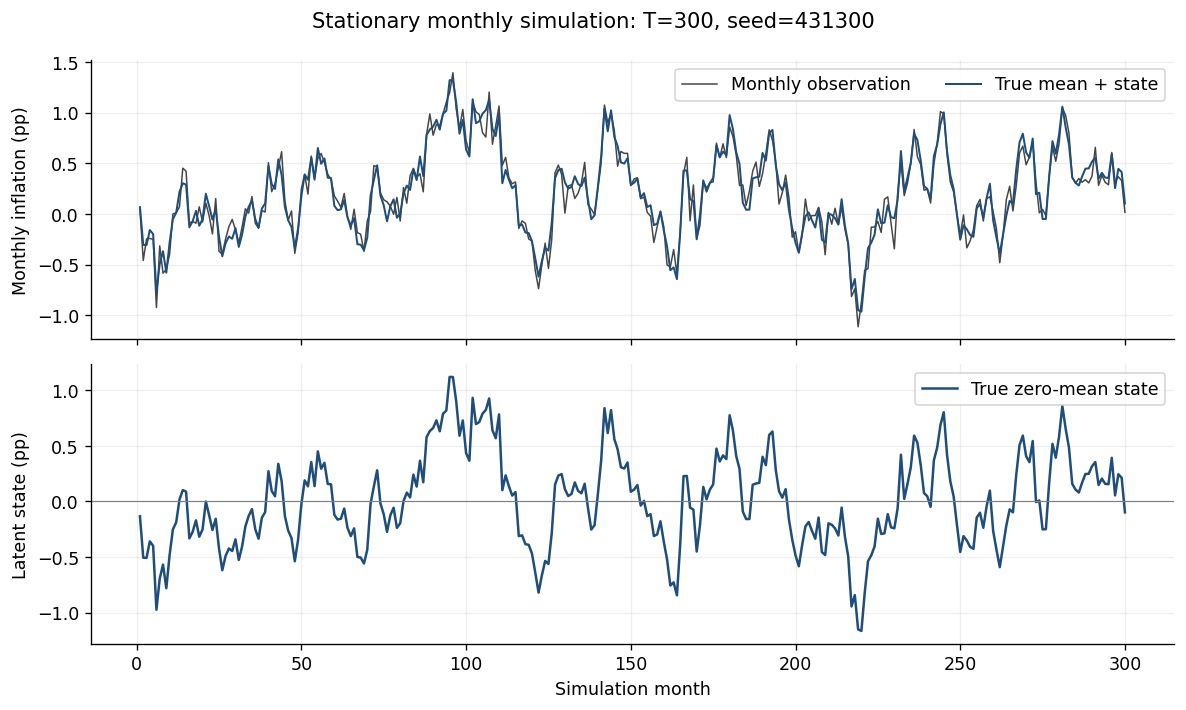

In [6]:
months = np.arange(1, T_sample+1)
fig_simulated, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(months, y_sim, color=COLORS['data'], lw=0.9, label='Monthly observation')
axes[0].plot(months, truth.mu+alpha_true, color=COLORS['monthly'], lw=1.2, label='True mean + state')
axes[0].set_ylabel('Monthly inflation (pp)'); axes[0].legend(ncol=2)
axes[1].plot(months, alpha_true, color=COLORS['monthly'], label='True zero-mean state')
axes[1].axhline(0, color='gray', lw=0.7)
axes[1].set_ylabel('Latent state (pp)'); axes[1].set_xlabel('Simulation month'); axes[1].legend()
fig_simulated.suptitle(f'Stationary monthly simulation: T={T_sample}, seed={SIMULATION_SEED}')
fig_simulated.tight_layout(); plt.show()

The latent process exhibits persistent departures from its zero mean, while observation shocks add transitory movements. This draw checks the intended data-generating process; estimator recovery is evaluated in Coding 2.